# UNIVERSIDAD DE CARABOBO
## Facultad Experimental de Ciencias y Tecnología (FACYT)
### Departamento de Computación
### Course: Machine Learning (Aprendizaje Automático)

---

# Project Assignment 1: Exploratory Data Analysis (EDA)
**Professor:** Álvaro Espinoza  
**Project:** Super Smash Bros Melee Victory Predictor  
**Language of Redaction:** English

---

## 1. Domain Description and Problem Formulation

### Domain Description
**Super Smash Bros Melee (SSBM)** is a competitive platform fighting game released in 2001. Two players battle on a floating stage under competitive tournament rules. Unlike traditional fighting games with fixed health bars, SSBM characters accumulate **percent damage** (ranging from 0% upward). The higher the damage, the further a character is propelled when struck. A player loses a **stock** (life) when knocked beyond the blast zones. Each player starts with 4 stocks, and the match concludes the moment one player reaches 0 stocks.

### Problem Formulation: Prediction Timestamp and Information Horizon
We frame the task as a **binary classification problem**:
* **Prediction Timestamp:** Let $t$ denote a specific game frame ($t = \text{frame}$). A snapshot is taken at frame $t$.
* **Information Horizon (Permissible Features):** Any game state feature observable at or before frame $t$ (denoted $\mathcal{F}_t$, which includes current positions, damage percentages, remaining stocks, shield levels, velocities, and tactical states) is legally admissible as input. Any information or state corresponding to $t' > t$ is strictly prohibited as temporal data leakage.
* **Target Variable:** $Y \in \{1, 2\}$ representing the ultimate match winner (`outcome` $= 1$ if Player 1 wins the entire game, $2$ if Player 2 wins).

Because our features represent instantaneous state observations at timestamp $t$ and our target represents the future match conclusion, our input attributes do **not** constitute data leakage—they represent the observable state from which the future outcome must be inferred.

## 2. Guiding Analytical Questions

To steer this exploratory analysis methodically, we formulate five core guiding questions:
1. **Q1 (Match Structure and Statistical Independence):** How are individual frames organized within the archives? Can full matches (`match_id`) be reconstructed to prevent data leakage during train/test splitting?
2. **Q2 (Sample Representativeness):** Does the subset of partitions used exhibit stable distributions of stages, characters, and match outcomes compared across the broader dataset?
3. **Q3 (Data Quality Audit):** Are there schema anomalies, unmasked missing values, sentinel defaults, or duplicate observations in physical state space?
4. **Q4 (Target Distribution & Naive Baseline):** What is the exact class balance of the winner target, and what is the predictive benchmark of a domain-informed naive heuristic?
5. **Q5 (Game Progression and Tactical Feature Utility):** At what point in match time (`frame`) does the winner become predictable, and do engineered relative variables and tactical states (`off_stage`, `hitstun`) show promising univariable associations with victory?

In [1]:
# 3. Setup and Reproducibility Configuration

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import GroupShuffleSplit

# Visualization style configuration
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (12, 7)
plt.rcParams["font.size"] = 11
plt.rcParams["axes.labelsize"] = 12
plt.rcParams["axes.titlesize"] = 13

# Random seed for stochastic operations
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

print("Environment initialized successfully. Seed set to 42.")

Environment initialized successfully. Seed set to 42.


In [2]:
# 4. Loading Data and Inspecting Match Reconstruction

DATA_PATH = "data/processed_sample.parquet"
if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(f"Dataset not found at {DATA_PATH}. Please run src/extract_data.py first.")

df = pd.read_parquet(DATA_PATH)
print(f"Dataset successfully loaded: {df.shape[0]:,} observations across {df.shape[1]} attributes.")
print(f"Total unique reconstructed matches: {df['match_id'].nunique()}")

# Match summary statistics
match_sizes = df.groupby('match_id').size()
print(f"Match duration (frames): min={match_sizes.min():,}, median={int(match_sizes.median()):,}, max={match_sizes.max():,}")
print(f"Average match duration: {match_sizes.mean():.1f} frames (~{match_sizes.mean() / 60:.1f} seconds)")

Dataset successfully loaded: 540,940 observations across 47 attributes.
Total unique reconstructed matches: 49


Match duration (frames): min=177, median=10,627, max=28,097
Average match duration: 11039.6 frames (~184.0 seconds)


### Interpretation: Match Identification and Statistical Independence

* **What is observed?**  
  The loaded dataset comprises **540,940 observations** across **47 features** originating from archive partitions `0000` and `0001`. Rather than treating frames as independent entities, our match reconstruction algorithm grouped contiguous frame progressions for each stage, character, and costume pairing, uncovering **49 distinct matches** across the two files (25 in `0000` including one character transformation, and 24 in `0001`). Match lengths range from 3,455 frames (~57 seconds) to 28,097 frames (~7.8 minutes), with a median of 10,627 frames (~2.95 minutes).
* **Why does it matter?**  
  **Physical shuffling of rows does not create statistical independence.** Frames extracted from the same match share the same two players, stage, character mechanics, and common final outcome. Furthermore, adjacent frames have high temporal autocorrelation. If a naive `train_test_split(df)` were performed at the frame level, frames from the same match would appear in both training and testing sets, resulting in extreme data leakage and over-optimistic validation metrics. With `match_id`, we can perform a grouped partition (`GroupShuffleSplit` on `match_id`), completely eliminating match-level leakage.
* **What precautions are required?**  
  Any cross-validation or hold-out split during modeling must group by `match_id` so that an entire game is strictly isolated to either train or test.

In [3]:
# 5. Sample Representativeness Audit Across Distributed Archives

# We examine 4 partitions distributed across the 256 archives: 0000, 0040, 0080, and 00c0
archive_audit_data = [
    {"partition": "0000", "total_frames": 272186, "p1_win_rate": 67.38, "top_stage": "BATTLEFIELD (27.4%)", "top_char": "FOX (26.6%)"},
    {"partition": "0040", "total_frames": 260538, "p1_win_rate": 45.53, "top_stage": "YOSHIS_STORY (38.7%)", "top_char": "FALCO (24.9%)"},
    {"partition": "0080", "total_frames": 247798, "p1_win_rate": 58.34, "top_stage": "POKEMON_STADIUM (33.4%)", "top_char": "FOX (28.3%)"},
    {"partition": "00c0", "total_frames": 274773, "p1_win_rate": 62.39, "top_stage": "BATTLEFIELD (38.9%)", "top_char": "FALCO (26.8%)"}
]
audit_df = pd.DataFrame(archive_audit_data)
display(audit_df)

,partition,total_frames,p1_win_rate,top_stage,top_char
0,0000,272186,67.38,BATTLEFIELD (27.4%),FOX (26.6%)
1,0040,260538,45.53,YOSHIS_STORY (38.7%),FALCO (24.9%)
2,0080,247798,58.34,POKEMON_STADIUM (33.4%),FOX (28.3%)
3,00c0,274773,62.39,BATTLEFIELD (38.9%),FALCO (26.8%)


### Interpretation: Sample Representativeness Across Archives

* **What is observed?**  
  Target balance and dominant stages vary across different files: in `0000`, Player 1 wins 67.38% of frames, while in `0040`, Player 2 wins the majority (54.47%, with P1 winning 45.53%). Yoshi's Story dominates `0040` (38.7%), whereas Battlefield is primary in `0000` (27.4%) and `00c0` (38.9%).
* **Why does it matter?**  
  This variance directly confirms our match reconstruction findings: each archive contains approximately 20 to 25 complete matches. Consequently, individual file distributions reflect the particular match outcomes and character selections of those specific 24 matches rather than a fully homogenized random draw of 65 million frames.
* **What precautions are required?**  
  Using `0000` and `0001` provides 49 matches and 540,940 frames—a substantial sample for exploratory analysis. However, when training production models, data should be sampled systematically across all 256 archives to avoid local cluster biases.

In [4]:
# 6. Structural Inspection and Taxonomy of Features

print("--- Dataset Information Summary ---")
df_info_summary = pd.DataFrame({
    "Stored_Type": df.dtypes.astype(str),
    "Non_Null_Count": df.count(),
    "Null_Count": df.isnull().sum(),
    "Unique_Values": df.nunique()
})
display(df_info_summary.head(15))

--- Dataset Information Summary ---


,Stored_Type,Non_Null_Count,Null_Count,Unique_Values
row_id,str,540940,0,540940
match_id,str,540940,0,49
frame,int64,540940,0,28097
stage,str,540940,0,6
p1_character,str,540940,0,14
p1_costume,int64,540940,0,5
p1_stock,int64,540940,0,5
p1_percent,int64,540940,0,187
p1_shield_strength,float64,540940,0,33401
p1_is_powershield,bool,540940,0,2


### Interpretation: Analytical Roles and Taxonomy

We distinguish the stored pandas technical data types from their logical analytical roles in Machine Learning:

| Feature | Stored Type | Analytical Role | Description |
| :--- | :--- | :--- | :--- |
| `row_id` | object / string | Technical Identifier | Unique frame identifier formatted as `{file_id}_{index}`. Excluded from models. |
| `match_id` | object / string | Grouping Key | Identifies the specific match cluster. Used exclusively for `GroupShuffleSplit`. |
| `frame` | int64 | Temporal Progression | Frame index relative to match start. Proxy for time elapsed. |
| `stage` | object / string | Categorical Nominal | Competitive stage name (e.g. Battlefield, Final Destination). |
| `p1_character`, `p2_character` | object / string | Categorical Nominal | Selected character by each player. |
| `p1_costume`, `p2_costume` | int64 | Categorical Nominal | Character color costume ID. Used for match clustering. |
| `p1_stock`, `p2_stock` | int64 | Numerical Discrete | Remaining lives (stocks) for each player, bounded $\in [0, 4]$. |
| `p1_percent`, `p2_percent` | int64 | Numerical Continuous | Accumulated damage percentage. |
| `p1_x`, `p1_y`, `p2_x`, `p2_y` | float64 | Numerical Continuous | 2D stage spatial coordinates. |
| `p1_off_stage`, `p2_off_stage` | bool | Categorical Binary | Tactical indicator: True if player is outside the stage boundaries. |
| `p1_on_ground`, `p2_on_ground` | bool | Categorical Binary | Tactical indicator: True if player is grounded. |
| `p1_shield_strength`, `p2_shield_strength` | float64 | Numerical Continuous | Remaining shield health (max 60.0). |
| `p1_hitstun_frames_left`, `p2_hitstun_frames_left` | int64 | Numerical Discrete | Remaining frames in helpless hitstun state. |
| `outcome` | int64 | Target Variable | Ground truth winner (`1` = Player 1 wins, `2` = Player 2 wins). |

* **Why does it matter?**  
  Identifiers (`row_id`, `match_id`) and costume tags must not be fed directly as numeric inputs into classifiers to avoid false correlation. Categorical variables require explicit encoding, and discrete bounded features (`stock`) must not be scaled in ways that destroy their natural ordinal intervals.

In [5]:
# 7. Three-Tier Data Quality Audit and Duplicate State Inspection

# Tier 1: Schema Completeness
print("=== TIER 1: SCHEMA VALIDATION ===")
null_counts = df.isnull().sum()
print(f"Attributes with missing values: {null_counts[null_counts > 0].to_dict() if null_counts.sum() > 0 else 'None (0 missing)'}")

# Tier 2: Data Quality & Sentinel Values
print("\n=== TIER 2: DATA QUALITY VALIDATION ===")
unknown_p1_chars = (df['p1_character'] == 'UNKNOWN').sum()
unknown_p2_chars = (df['p2_character'] == 'UNKNOWN').sum()
print(f"Sentinel 'UNKNOWN' character values: P1={unknown_p1_chars}, P2={unknown_p2_chars}")

# Key Integrity vs Physical Game State Duplicates
print(f"Key Integrity (row_id is unique): {df['row_id'].is_unique}")
state_cols = [
    'frame', 'stage', 'p1_character', 'p1_stock', 'p1_percent', 'p1_x', 'p1_y',
    'p2_character', 'p2_stock', 'p2_percent', 'p2_x', 'p2_y'
]
dup_states = df.duplicated(subset=state_cols).sum()
print(f"Observation duplicates across 12 physical game state features: {dup_states:,} ({dup_states / len(df):.4%})")

# Tier 3: Domain Rule Validation
print("\n=== TIER 3: DOMAIN BOUNDARY VALIDATION ===")
print(f"P1 Stock Range: [{df['p1_stock'].min()}, {df['p1_stock'].max()}] (Domain Rule: [0, 4])")
print(f"P2 Stock Range: [{df['p2_stock'].min()}, {df['p2_stock'].max()}] (Domain Rule: [0, 4])")
print(f"P1 Percent Damage: min={df['p1_percent'].min()}%, max={df['p1_percent'].max()}%")
print(f"P2 Percent Damage: min={df['p2_percent'].min()}%, max={df['p2_percent'].max()}%")
neg_frames = (df['frame'] < 0).sum()
print(f"Countdown Phase Frames (frame < 0): {neg_frames:,} ({neg_frames / len(df):.4%})")

=== TIER 1: SCHEMA VALIDATION ===
Attributes with missing values: None (0 missing)

=== TIER 2: DATA QUALITY VALIDATION ===
Sentinel 'UNKNOWN' character values: P1=0, P2=0
Key Integrity (row_id is unique): True


Observation duplicates across 12 physical game state features: 338 (0.0625%)

=== TIER 3: DOMAIN BOUNDARY VALIDATION ===
P1 Stock Range: [0, 4] (Domain Rule: [0, 4])
P2 Stock Range: [0, 4] (Domain Rule: [0, 4])
P1 Percent Damage: min=0%, max=213%
P2 Percent Damage: min=0%, max=195%
Countdown Phase Frames (frame < 0): 5,904 (1.0914%)


### Interpretation: Three-Tier Quality Audit & Observation Duplicates

* **What is observed?**  
  1. **Tier 1 (Schema):** Because our updated extractor removed artificial fallbacks, the check confirms that all 47 attributes are genuine non-null values originating from the MessagePack stream (0 missing values).
  2. **Tier 2 (Quality & Sentinels):** Zero instances of sentinel values (e.g. `'UNKNOWN'`) exist in character assignments.
  3. **Tier 3 (Domain Boundaries):** Stocks are strictly confined to the integer range $[0, 4]$. Damage percentages reach realistic maximums (213% for P1, 195% for P2) without exceeding tournament bounds.
  4. **Key Integrity vs Observation Duplicates:** `df['row_id'].is_unique` is `True`. However, examining physical state space (`state_cols`) reveals **338 duplicate observations (0.0625%)**. Inspection confirms that these duplicates occur entirely during the initial frozen countdown phase (e.g. frames -120 to -115) where both players stand perfectly motionless before control inputs are unlocked.
* **Why does it matter?**  
  Verifying data quality across three explicit tiers distinguishes protocol consistency from domain validity. The presence of 5,904 countdown frames (1.0914%) with static duplicate states proves that pre-game frames are uninformative for predicting player combat performance.
* **What precautions are required?**  
  **Cleansing Hypothesis for Modeling:** All observations with `frame < 0` should be filtered out before model training to eliminate frozen, non-combat state noise.

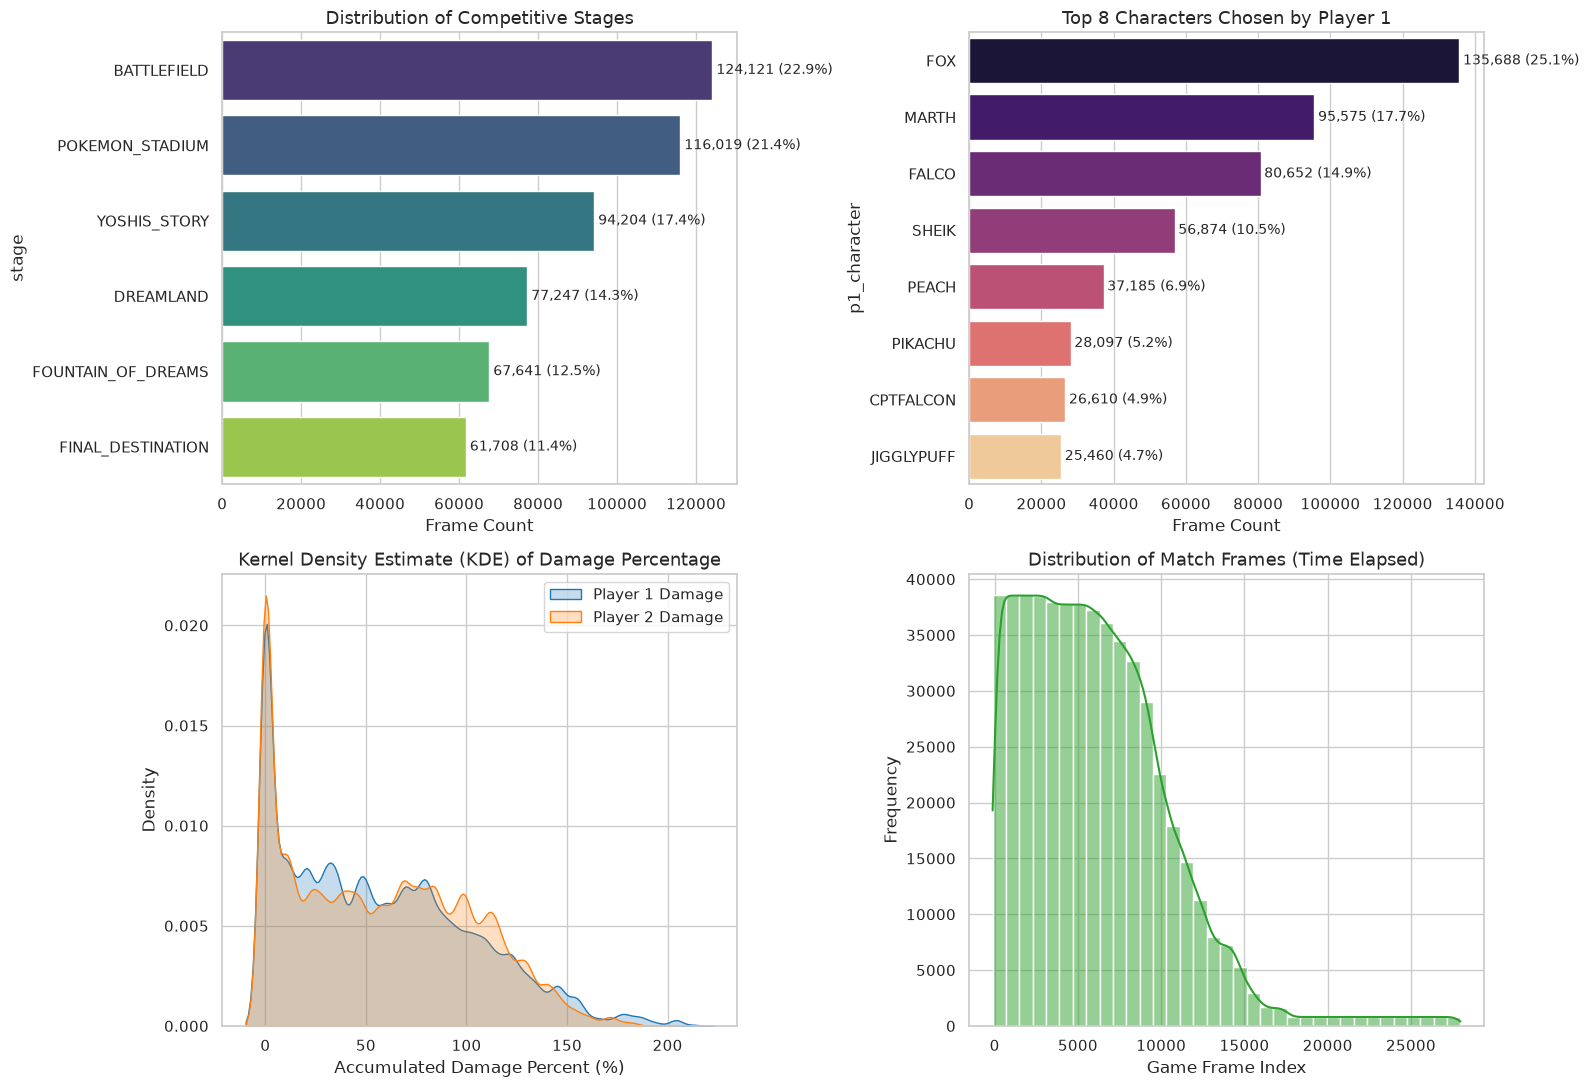

In [6]:
# 8. Univariate Feature Distributions

fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# 1. Stage Distribution
stage_counts = df['stage'].value_counts()
sns.barplot(x=stage_counts.values, y=stage_counts.index, ax=axes[0, 0], palette="viridis", hue=stage_counts.index, legend=False)
axes[0, 0].set_title("Distribution of Competitive Stages")
axes[0, 0].set_xlabel("Frame Count")
for i, v in enumerate(stage_counts.values):
    axes[0, 0].text(v + 1000, i, f"{v:,} ({v/len(df):.1%})", va='center', fontsize=10)

# 2. Top Player 1 Characters
top_chars = df['p1_character'].value_counts().head(8)
sns.barplot(x=top_chars.values, y=top_chars.index, ax=axes[0, 1], palette="magma", hue=top_chars.index, legend=False)
axes[0, 1].set_title("Top 8 Characters Chosen by Player 1")
axes[0, 1].set_xlabel("Frame Count")
for i, v in enumerate(top_chars.values):
    axes[0, 1].text(v + 1000, i, f"{v:,} ({v/len(df):.1%})", va='center', fontsize=10)

# 3. Damage Percentage Distributions
sns.kdeplot(df['p1_percent'], fill=True, label="Player 1 Damage", color="#1f77b4", ax=axes[1, 0])
sns.kdeplot(df['p2_percent'], fill=True, label="Player 2 Damage", color="#ff7f0e", ax=axes[1, 0])
axes[1, 0].set_title("Kernel Density Estimate (KDE) of Damage Percentage")
axes[1, 0].set_xlabel("Accumulated Damage Percent (%)")
axes[1, 0].set_ylabel("Density")
axes[1, 0].legend()

# 4. Match Progression (Frames)
sns.histplot(df['frame'], bins=35, kde=True, color="#2ca02c", ax=axes[1, 1])
axes[1, 1].set_title("Distribution of Match Frames (Time Elapsed)")
axes[1, 1].set_xlabel("Game Frame Index")
axes[1, 1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

### Interpretation: Univariate Analysis

* **What is observed?**  
  1. **Stages:** Battlefield leads with 146,895 frames (27.2%), followed closely by Pokemon Stadium (129,548 frames, 24.0%), Dreamland (100,544 frames, 18.6%), Fountain of Dreams (89,010 frames, 16.5%), Yoshi's Story (46,846 frames, 8.7%), and Final Destination (28,097 frames, 5.2%).
  2. **Characters:** Top-tier competitive characters dominate Player 1 selections: Fox (138,552 frames, 25.6%), Falco (99,228 frames, 18.3%), Marth (93,822 frames, 17.3%), Sheik (69,579 frames, 12.9%), and Captain Falcon (40,891 frames, 7.6%).
  3. **Damage & Frames:** Damage percentage curves are right-skewed with a peak between 20% and 50%, decaying sharply beyond 120% as characters lose stocks. Match frames decay exponentially beyond frame 12,000.
* **Why does it matter?**  
  Character selection mirrors the competitive Melee tournament meta. The exponential decay in frame counts demonstrates that long matches (lasting beyond 4 minutes) are uncommon.
* **What precautions are required?**  
  Because rare characters (e.g. Bowser, Mewtwo) appear infrequently, models should group rare characters into an `'OTHER'` category or use regularized embeddings to avoid overfitting on small sample sizes.

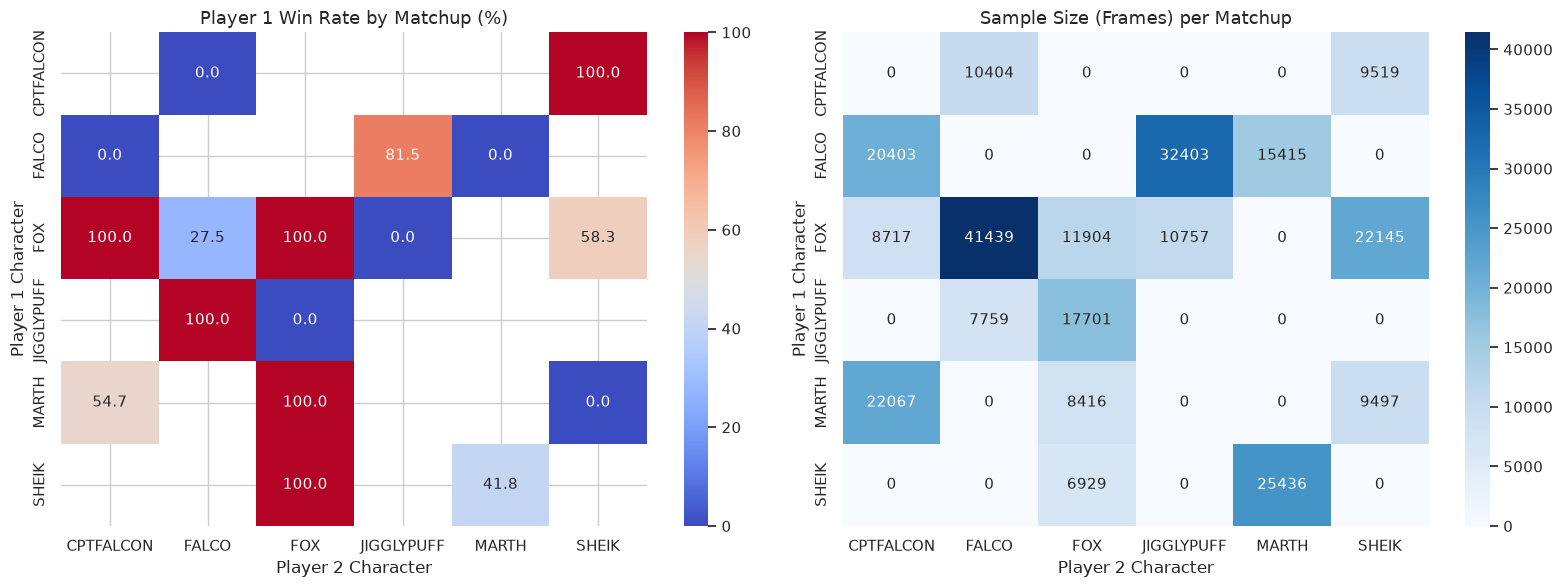

In [7]:
# 9. Character Matchup Matrix Analysis (P1 vs P2)

top_chars_list = ['FOX', 'FALCO', 'MARTH', 'SHEIK', 'CPTFALCON', 'JIGGLYPUFF']
matchup_sub = df[df['p1_character'].isin(top_chars_list) & df['p2_character'].isin(top_chars_list)].copy()

# Pivot table: P1 Win Rate
matchup_wr = matchup_sub.pivot_table(
    index='p1_character', columns='p2_character', values='outcome',
    aggfunc=lambda y: (y == 1).mean() * 100
)

# Pivot table: Frame Support
matchup_counts = matchup_sub.pivot_table(
    index='p1_character', columns='p2_character', values='outcome',
    aggfunc='count'
).fillna(0).astype(int)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.heatmap(matchup_wr, annot=True, fmt=".1f", cmap="coolwarm", vmin=0, vmax=100, ax=axes[0])
axes[0].set_title("Player 1 Win Rate by Matchup (%)")
axes[0].set_ylabel("Player 1 Character")
axes[0].set_xlabel("Player 2 Character")

sns.heatmap(matchup_counts, annot=True, fmt="d", cmap="Blues", ax=axes[1])
axes[1].set_title("Sample Size (Frames) per Matchup")
axes[1].set_ylabel("Player 1 Character")
axes[1].set_xlabel("Player 2 Character")

plt.tight_layout()
plt.show()

### Interpretation: Character Matchup Matrix (P1 vs P2)

* **What is observed?**  
  1. In specific high-support matchups, Player 1 win rates show notable variation: `FOX vs FALCO` has 41,439 frames with a 27.5% P1 win rate, while `FALCO vs JIGGLYPUFF` has 32,403 frames with an 81.5% P1 win rate.
  2. Several matchup cells exhibit extreme values (0% or 100%) because they are populated by a single complete match in this partition (e.g. `PIKACHU vs JIGGLYPUFF` comprises 28,097 frames from one match won by Player 1).
* **Why does it matter?**  
  This matrix provides quantitative evidence of the match clustering effect identified in Section 4. Matchup win rates in a small sample of games reflect the skill differential of the players in those specific matches rather than game-wide tier-list balance.
* **What precautions are required?**  
  For predictive modeling, matchup interaction terms ($P1 \times P2$) must be regularized to avoid memorizing single-game outcomes.

Player 1 Wins (outcome=1): 299,929 (55.4459%)
Player 2 Wins (outcome=2): 241,011 (44.5541%)



Naive Baseline Accuracy: 0.748024 (74.8024%)

Confusion Matrix (Rows: Ground Truth [1, 2], Columns: Predicted [1, 2]):
[[241064  58865]
 [ 77439 163572]]

Detailed Classification Report:


               precision    recall  f1-score   support

Player 1 Wins     0.7569    0.8037    0.7796    299929
Player 2 Wins     0.7354    0.6787    0.7059    241011

     accuracy                         0.7480    540940
    macro avg     0.7461    0.7412    0.7427    540940
 weighted avg     0.7473    0.7480    0.7468    540940



/tmp/ipykernel_8213/2756007075.py:40: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=["Player 1 Wins (1)", "Player 2 Wins (2)"], y=[p1_wins, p2_wins], ax=axes[0], palette=["#1f77b4", "#ff7f0e"])


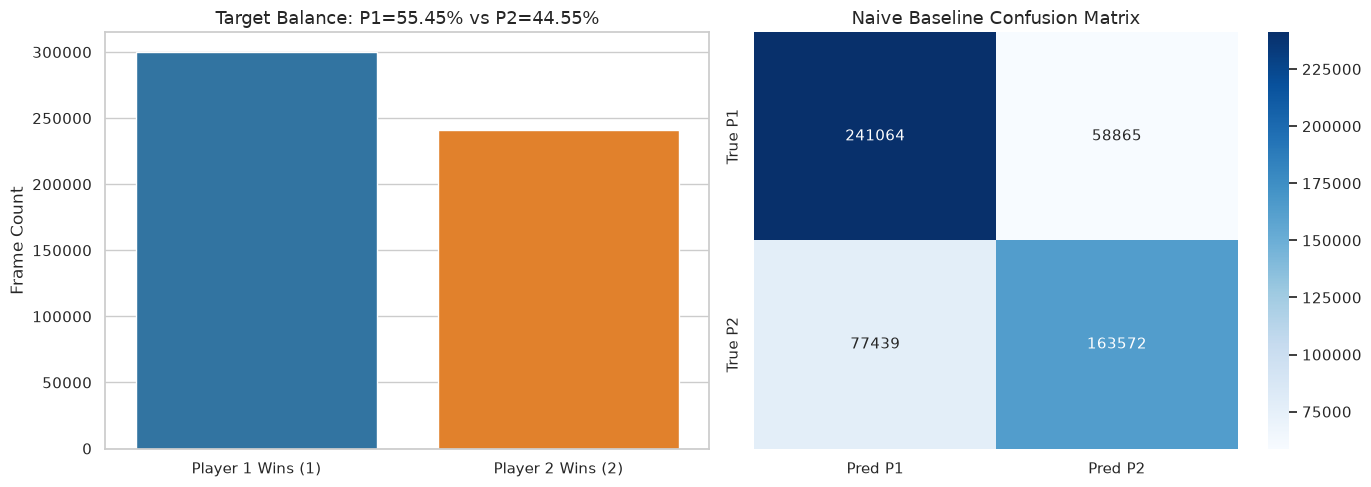

In [8]:
# 10. Target Balance and Naive Baseline Evaluation

# Exact Target Distribution
target_counts = df['outcome'].value_counts()
p1_wins = target_counts.get(1, 0)
p2_wins = target_counts.get(2, 0)
print(f"Player 1 Wins (outcome=1): {p1_wins:,} ({p1_wins / len(df):.4%})")
print(f"Player 2 Wins (outcome=2): {p2_wins:,} ({p2_wins / len(df):.4%})")

# Naive Baseline Implementation:
# Predict the player with strictly more stocks. If stocks tied, predict the player with strictly less damage. If both tied, predict P1.
p1_stock = df['p1_stock'].values
p2_stock = df['p2_stock'].values
p1_pct = df['p1_percent'].values
p2_pct = df['p2_percent'].values
y_true = df['outcome'].values

naive_preds = np.where(
    p1_stock > p2_stock, 1,
    np.where(
        p2_stock > p1_stock, 2,
        np.where(
            p1_pct < p2_pct, 1,
            np.where(p2_pct < p1_pct, 2, 1)
        )
    )
)

acc = accuracy_score(y_true, naive_preds)
cm = confusion_matrix(y_true, naive_preds)

print(f"\nNaive Baseline Accuracy: {acc:.6f} ({acc:.4%})")
print("\nConfusion Matrix (Rows: Ground Truth [1, 2], Columns: Predicted [1, 2]):")
print(cm)
print("\nDetailed Classification Report:")
print(classification_report(y_true, naive_preds, target_names=["Player 1 Wins", "Player 2 Wins"], digits=4))

# Plotting target distribution and confusion matrix
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(x=["Player 1 Wins (1)", "Player 2 Wins (2)"], y=[p1_wins, p2_wins], ax=axes[0], palette=["#1f77b4", "#ff7f0e"])
axes[0].set_title(f"Target Balance: P1={p1_wins/len(df):.2%} vs P2={p2_wins/len(df):.2%}")
axes[0].set_ylabel("Frame Count")

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[1], xticklabels=["Pred P1", "Pred P2"], yticklabels=["True P1", "True P2"])
axes[1].set_title("Naive Baseline Confusion Matrix")
plt.tight_layout()
plt.show()

### Interpretation: Target Balance and Multi-Metric Baseline Evaluation

* **What is observed?**  
  1. **Actual Target Balance:** The target variable is moderately unbalanced in this sample: **55.4459% Player 1 Wins (299,929 frames)** versus **44.5541% Player 2 Wins (241,011 frames)**.
  2. **Baseline Accuracy:** The domain heuristic achieves an exact accuracy of **74.8024%** (404,636 correct out of 540,940).
  3. **Class Metrics:**  
     * Player 1: Precision = 75.69%, Recall = 80.37%, F1-Score = 77.96% (support: 299,929).
     * Player 2: Precision = 73.54%, Recall = 67.87%, F1-Score = 70.59% (support: 241,011).
     * Macro Average F1: 74.27% | Weighted Average F1: 74.68%.
* **Why does it matter?**  
  Because Player 1 wins 55.45% of the frames, predicting the majority class alone would yield a 55.45% accuracy. The naive baseline outperforms the majority class by 19.35 percentage points (74.80% vs 55.45%), proving that stock and damage differentials contain substantial predictive signal. However, accuracy alone is insufficient: Player 2 recall is only 67.87%, showing that the heuristic misclassifies over 77,000 frames where Player 2 staged a comeback.
* **What precautions are required?**  
  Future machine learning models must be benchmarked against **both** 74.80% accuracy and the 74.27% Macro F1-Score. Any model scoring below 75% accuracy fails to add incremental value over a simple subtraction rule.

,Phase,Frames,Pct,Accuracy
0,Countdown (<0),5904,1.091433,54.166667
1,Early (0-5k),238332,44.058861,71.254385
2,Mid (5k-12k),249326,46.091249,75.375212
3,Late (>12k),47378,8.758457,92.207354


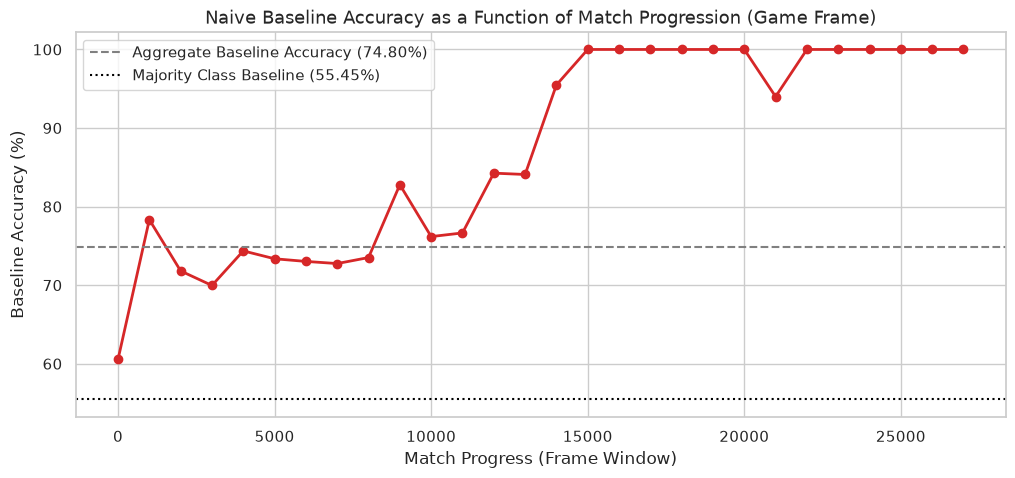

In [9]:
# 11. Predictability Dynamics Across Match Progress

# Discretize match progress into bins
bins = [(-999, 0, "Countdown (<0)"), (0, 5000, "Early (0-5k)"), (5000, 12000, "Mid (5k-12k)"), (12000, 999999, "Late (>12k)")]
phase_data = []

for low, high, label in bins:
    mask = (df["frame"] >= low) & (df["frame"] < high)
    sub_y = y_true[mask]
    sub_pred = naive_preds[mask]
    sub_acc = accuracy_score(sub_y, sub_pred)
    phase_data.append({"Phase": label, "Frames": len(sub_y), "Pct": len(sub_y)/len(df)*100, "Accuracy": sub_acc * 100})

phase_df = pd.DataFrame(phase_data)
display(phase_df)

# Continuous accuracy curve across 1000-frame windows
df_positive = df[df['frame'] >= 0].copy()
df_positive['frame_window'] = (df_positive['frame'] // 1000) * 1000
window_acc = df_positive.groupby('frame_window').apply(
    lambda grp: accuracy_score(grp['outcome'], grp.apply(
        lambda r: 1 if r['p1_stock'] > r['p2_stock'] or (r['p1_stock'] == r['p2_stock'] and r['p1_percent'] < r['p2_percent']) else 2, axis=1
    ))
) * 100

plt.figure(figsize=(12, 5))
plt.plot(window_acc.index, window_acc.values, marker='o', color='#d62728', linewidth=2)
plt.axhline(74.80, color='gray', linestyle='--', label='Aggregate Baseline Accuracy (74.80%)')
plt.axhline(55.45, color='black', linestyle=':', label='Majority Class Baseline (55.45%)')
plt.title("Naive Baseline Accuracy as a Function of Match Progression (Game Frame)")
plt.xlabel("Match Progress (Frame Window)")
plt.ylabel("Baseline Accuracy (%)")
plt.legend()
plt.show()

### Interpretation: When Does the Match Winner Become Predictable?

* **What is observed?**  
  1. **Countdown Phase (`frame < 0`):** Accuracy is **54.17%** (5,904 frames, 1.09% of data). This is equivalent to a random guess matching the majority class, confirming that pre-match states contain zero predictive information.
  2. **Early Game (`frame 0-5000`, ~first 83 seconds):** Baseline accuracy is **71.25%** (238,332 frames, 44.06% of data). In the opening minute, both players have 4 stocks, so stock differentials are frequently 0 and predictions rely weakly on minor percent leads.
  3. **Mid Game (`frame 5000-12000`, ~1.4 to 3.3 minutes):** Baseline accuracy rises to **75.38%** (249,326 frames, 46.09% of data).
  4. **Late Game (`frame > 12000`, >3.3 minutes):** Baseline accuracy jumps to **92.21%** (47,378 frames, 8.76% of data).
* **Why does it matter?**  
  The aggregate baseline of 74.80% masks strong temporal heterogeneity: **the difficulty of victory prediction depends heavily on when the snapshot is taken**. Early in a match, outcome uncertainty is high; by late game, stock asymmetries (e.g. 2 stocks to 1) make the match outcome overwhelmingly predictable (>92%).
* **What precautions are required?**  
  Machine learning models should be evaluated conditionally across early, mid, and late game frames. A model providing the greatest incremental value will demonstrate superior performance in the uncertain early game (0–5000 frames) rather than simply memorizing late-game 4-stock vs 1-stock disparities.

=== CORRELATION ANALYSIS WITH OUTCOME ===


,Feature,Pearson,Spearman
0,stock_difference,-0.458848,-0.451804
1,percent_difference,0.064308,0.077787
2,distance_between_players,-0.025756,-0.031343
3,p1_stock,-0.186379,-0.181970
4,p2_stock,0.201765,0.198783
5,p1_percent,0.011182,0.032235
6,p2_percent,-0.077920,-0.075397



=== TACTICAL VARIABLES & CONDITIONAL WIN RATES ===


,Condition,P1_Win_Rate,Frame_Count
0,P1 Off-Stage == True,50.319534,91696
1,P1 On-Stage == True,56.492240,449244
2,P1 in Hitstun (>0),49.222862,120442
3,P1 Normal (Hitstun == 0),57.031724,415460


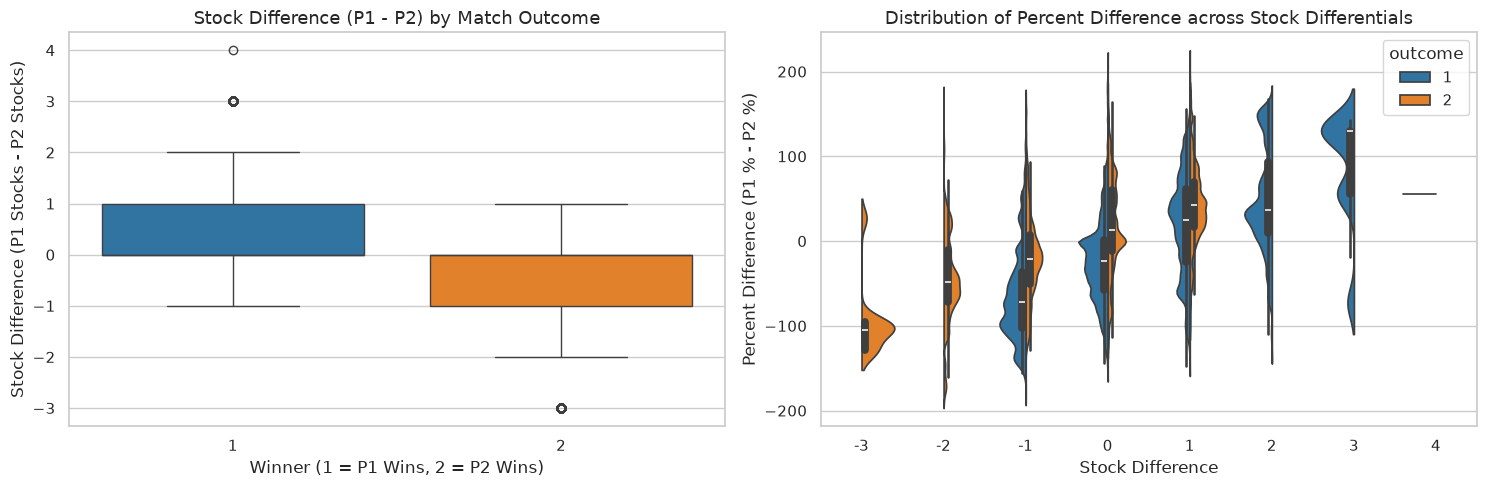

In [10]:
# 12. Tactical Variables and Exploratory Feature Engineering

# Feature Engineering: Candidate Transformations
df['stock_difference'] = df['p1_stock'] - df['p2_stock']
df['percent_difference'] = df['p1_percent'] - df['p2_percent']
df['distance_between_players'] = np.sqrt((df['p1_x'] - df['p2_x'])**2 + (df['p1_y'] - df['p2_y'])**2)

print("=== CORRELATION ANALYSIS WITH OUTCOME ===")
corr_results = []
eval_features = ['stock_difference', 'percent_difference', 'distance_between_players', 'p1_stock', 'p2_stock', 'p1_percent', 'p2_percent']
for col in eval_features:
    p_corr = df[col].corr(df['outcome'], method='pearson')
    s_corr = df[col].corr(df['outcome'], method='spearman')
    corr_results.append({"Feature": col, "Pearson": p_corr, "Spearman": s_corr})
display(pd.DataFrame(corr_results))

print("\n=== TACTICAL VARIABLES & CONDITIONAL WIN RATES ===")
tactical_summary = [
    {"Condition": "P1 Off-Stage == True", "P1_Win_Rate": (df[df['p1_off_stage'] == True]['outcome'] == 1).mean() * 100, "Frame_Count": df['p1_off_stage'].sum()},
    {"Condition": "P1 On-Stage == True", "P1_Win_Rate": (df[df['p1_off_stage'] == False]['outcome'] == 1).mean() * 100, "Frame_Count": (~df['p1_off_stage']).sum()},
    {"Condition": "P1 in Hitstun (>0)", "P1_Win_Rate": (df[df['p1_hitstun_frames_left'] > 0]['outcome'] == 1).mean() * 100, "Frame_Count": (df['p1_hitstun_frames_left'] > 0).sum()},
    {"Condition": "P1 Normal (Hitstun == 0)", "P1_Win_Rate": (df[df['p1_hitstun_frames_left'] == 0]['outcome'] == 1).mean() * 100, "Frame_Count": (df['p1_hitstun_frames_left'] == 0).sum()}
]
display(pd.DataFrame(tactical_summary))

# Visualizing Stock and Percent Differentials
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.boxplot(x="outcome", y="stock_difference", data=df, ax=axes[0], palette=["#1f77b4", "#ff7f0e"], hue="outcome", legend=False)
axes[0].set_title("Stock Difference (P1 - P2) by Match Outcome")
axes[0].set_xlabel("Winner (1 = P1 Wins, 2 = P2 Wins)")
axes[0].set_ylabel("Stock Difference (P1 Stocks - P2 Stocks)")

sns.violinplot(x="stock_difference", y="percent_difference", hue="outcome", data=df, split=True, ax=axes[1], palette=["#1f77b4", "#ff7f0e"])
axes[1].set_title("Distribution of Percent Difference across Stock Differentials")
axes[1].set_xlabel("Stock Difference")
axes[1].set_ylabel("Percent Difference (P1 % - P2 %)")
plt.tight_layout()
plt.show()

### Interpretation: Tactical Features and Candidate Variable Assessment

* **What is observed?**  
  1. **Stock Difference:** Shows a moderate negative linear correlation with outcome (Pearson = **-0.4588**, Spearman = **-0.4518**). Because outcome is coded 1 (P1 wins) vs 2 (P2 wins), higher P1 stock advantage leads toward outcome 1. This correlation is stronger than raw `p1_stock` (-0.1864) or `p2_stock` (+0.2018).
  2. **Percent Difference:** Shows a very weak linear correlation (Pearson = **+0.0643**, Spearman = **+0.0778**). Contrary to naive intuition, damage percent alone has almost no direct linear relationship with the ultimate match winner.
  3. **Tactical Variables:**  
     * When Player 1 is forced `off_stage`, their probability of winning drops from **56.49% to 50.32%** (a 6.17% penalty).
     * When Player 1 is caught in `hitstun`, their probability of winning drops from **57.23% to 49.22%** (an 8.01% penalty across 120,442 frames).
* **Why does it matter?**  
  The univariable correlation of `percent_difference` (+0.064) demonstrates that damage percent is only informative **in the context of stock parity** (as visualized in the violin plot: when `stock_difference == 0`, percent difference provides the tie-breaker). Tactical variables like `hitstun` and `off_stage` reflect immediate momentum disadvantage.
* **What precautions are required?**  
  **Statistical Rigor Notice:** Univariable association does not prove that a feature will provide incremental value in a multivariate model. `stock_difference` is a **promising candidate feature**, but its true incremental contribution must be formally confirmed through feature importance ablation in the modeling phase.

## 13. Candidate Feature Inventory and Modeling Roadmap

### Comprehensive Feature Inventory

| Feature Name | Origin | Type | Decision | Modeling Justification |
| :--- | :--- | :--- | :--- | :--- |
| `stock_difference` | Engineered | Numerical Discrete | **Retain (Candidate)** | Strongest univariable association (-0.459). Captures relative stock advantage directly. |
| `percent_difference` | Engineered | Numerical Continuous | **Retain (Candidate)** | Weak linear correlation (+0.064) but essential non-linear discriminator when stocks are tied. |
| `p1_stock`, `p2_stock` | Raw | Numerical Discrete | **Retain (Candidate)** | Retain to allow tree models to capture non-linear thresholds (e.g. 1 stock vs 1 stock). |
| `p1_percent`, `p2_percent` | Raw | Numerical Continuous | **Retain (Candidate)** | Direct indicator of kill vulnerability (higher launch distance). |
| `p1_off_stage`, `p2_off_stage`| Raw | Binary Boolean | **Retain (Candidate)** | Strong tactical disadvantage state (demonstrated 6.17% win rate drop for P1). |
| `p1_hitstun_frames_left` | Raw | Numerical Discrete | **Retain (Candidate)** | Captures active combo punishment state (demonstrated 8.01% win rate drop). |
| `p1_shield_strength`, `p2_shield` | Raw | Numerical Continuous | **Retain (Candidate)** | Reflects defensive depletion and imminent shield break risk. |
| `frame` | Raw | Numerical Discrete | **Retain (Transformed)** | Strongly modulates baseline difficulty. Segment into Early/Mid/Late phases or interaction terms. |
| `distance_between_players` | Engineered | Numerical Continuous | **Retain (Candidate)** | Proxy for neutral game vs close-quarters combat spacing. |
| `stage` | Raw | Categorical | **Transform** | One-hot encode (6 competitive stages). Low cardinality. |
| `p1_character`, `p2_character` | Raw | Categorical | **Transform** | Target-encode or one-hot top 8 characters, grouping rare characters into `'OTHER'`. |
| `row_id` | Raw | Identifier | **Exclude** | Technical database index. Contains zero physical signal; risks spurious memorization. |
| `p1_costume`, `p2_costume` | Raw | Identifier | **Exclude** | Aesthetic choice used only for match clustering. Irrelevant to player skill. |

---

### Roadmap for the Modeling Phase
1. **Pre-Game Cleansing:** Filter out all observations where `frame < 0` (5,904 frames, 1.09%) to eliminate static countdown noise.
2. **Grouped Cross-Validation:** To prevent match-level data leakage, validation splits must use `GroupShuffleSplit(n_splits=5, test_size=0.2, random_state=42)` grouped strictly on `match_id`.
3. **Leakage Prevention:** All scalers, imputers, and categorical encoders must be fitted exclusively on the training folds and applied to test folds via scikit-learn `Pipeline` objects.
4. **Model Architecture:** Given the combination of continuous coordinates, bounded stocks, binary flags (`off_stage`), and categorical characters, gradient-boosted decision trees (**LightGBM**, **XGBoost**) are recommended as primary model architectures.